In [20]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer
import torch
from torch import nn
import matplotlib.pyplot as plt
import time

In [21]:
df = pd.read_csv('./data/SMSSpamCollection', sep='\t', names=['type', 'message'])
df['spam'] = df['type'] == 'spam'
df = df.drop(columns=['type'])

cv = CountVectorizer(max_features=1000)
messages = cv.fit_transform(df['message'])

X = torch.tensor(
    messages.todense(), dtype=torch.float32
)
y = torch.tensor(
    df['spam'], dtype=torch.float32
).reshape((-1, 1))

print(X.shape, y.shape)

torch.Size([5572, 1000]) torch.Size([5572, 1])


In [40]:
model = nn.Linear(1000, 1)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
losses = []

It taks 7.701680898666382 to finish!


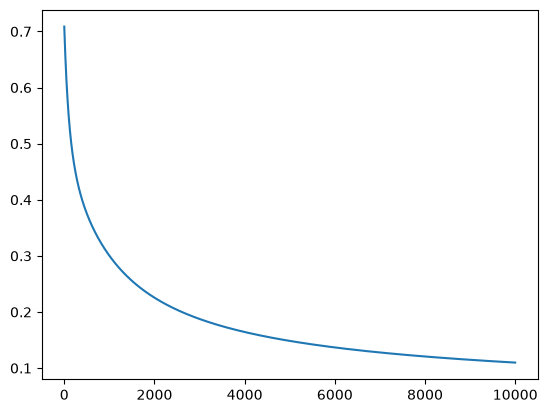

In [41]:
t_time = time.time()
for i in range(0, 10000):
    model.zero_grad()
    outputs = model(X)
    loss = loss_fn(outputs, y)
    loss.backward()
    optimizer.step()
    
    # if i % 100 == 0:
    #     print(loss)
    
    losses.append(loss.item())
e_time = time.time()
print(f'It taks {e_time - t_time} to finish!')
plt.plot(losses)
plt.show()

In [44]:
model.eval()

with torch.no_grad():
    y_pred =nn.functional.sigmoid(model(X)) > 0.25
    print(f'Accuracy: {(y_pred == y)\
        .type(torch.float32).mean()}')
    
    print(f'Sensitivity: {(y_pred[y==1] == y[y==1])\
        .type(torch.float32).mean()}')
    
    print(f'Specificity: {(y_pred[y==0] == y[y==0])\
        .type(torch.float32).mean()}')
    
    print(f'percision: {(y_pred[y_pred==1] == y[y_pred==1])\
        .type(torch.float32).mean()}')

Accuracy: 0.9761306643486023
Sensitivity: 0.9103078842163086
Specificity: 0.9863212704658508
percision: 0.9115281701087952
